# Approach 4: sentence embeddings + linear SVM

Experiment on the prepared escalation package (`prepare_data.py` → `data/`). **Target:** any recorded escalation, regardless of manager approval. **Inputs:** prepared `model_text` only (cleaned short description + description). No incident linkage, assignment group or outcome fields are predictors.

The frozen `sentence-transformers/all-MiniLM-L6-v2` encoder produces 384-dimensional, L2-normalised embeddings. A **linear SVM** (`sklearn.svm.LinearSVC`, squared-hinge loss) learns the escalation classifier. Encoder documentation: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2

**Evaluation policy fixed before test evaluation (same as Approach 3):** choose regularisation C by validation average precision; select the alert threshold by validation escalation F1 (ties favour precision). Report this threshold and the SVM default margin (0), alongside always-alert and always-negative benchmarks. Never tune on test results.

**SVM-specific note:** `LinearSVC` has no probabilities. Scores are signed distances to the margin (`decision_function`), so the default threshold is 0 rather than 0.5 and no Brier score is reported. Ranking metrics (average precision, ROC AUC) are unaffected.

**Limitations:** synthetic data; retrospective outcome labels; no verified initial snapshots; repeated text templates. This is a prototype evaluation, not evidence of live early-warning accuracy. Test unseen-text subsets are a secondary diagnostic, not an independent holdout.

The notebook contains four experiments, each building on the last: (1) text-only SVM with F1 threshold, (2) the same model with a recall ≥ 90% threshold that minimises false positives, (3) text + category + subcategory + assumed initial priority, (4) nested five-fold grouped cross-validation. A results summary is at the end.

In [1]:
from pathlib import Path
import json, hashlib, platform, importlib.metadata, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.svm import LinearSVC
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, roc_curve,
    classification_report)
from IPython.display import display
BASE = Path.cwd()
if not (BASE / 'data').exists():
    raise RuntimeError('Run this notebook with its containing model_approach4_svm folder as the working directory.')
RESULTS = BASE / 'results'; RESULTS.mkdir(exist_ok=True)
SEED = 42
np.random.seed(SEED)
MODEL_ID = 'sentence-transformers/all-MiniLM-L6-v2'
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]
MIN_RECALL = 0.90

def fit_svm(C, X, y):
    """LinearSVC that must converge (a ConvergenceWarning is treated as an error)."""
    clf = LinearSVC(C=C, loss='squared_hinge', dual='auto', max_iter=20000, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        clf.fit(X, y)
    return clf

def threshold_table(truth, score):
    """Every distinct score as an alert threshold (alert if score >= t), vectorised."""
    truth = np.asarray(truth); order = np.argsort(-score, kind='stable')
    s, t = score[order], truth[order]
    tp, fp = np.cumsum(t), np.cumsum(1 - t)
    last = np.r_[s[1:] != s[:-1], True]            # last row of each distinct score
    P, N = t.sum(), (1 - t).sum()
    tbl = pd.DataFrame({'threshold': s[last], 'tp': tp[last], 'fp': fp[last]})
    tbl['fn'] = P - tbl.tp; tbl['tn'] = N - tbl.fp
    tbl['recall'] = tbl.tp / P; tbl['precision'] = tbl.tp / (tbl.tp + tbl.fp)
    tbl['f1'] = 2 * tbl.precision * tbl.recall / (tbl.precision + tbl.recall)
    tbl['alert_rate'] = (tbl.tp + tbl.fp) / len(t)
    return tbl

def pick_f1_threshold(truth, score):
    tbl = threshold_table(truth, score)
    return tbl, tbl.sort_values(['f1', 'precision', 'threshold'], ascending=[False, False, False]).iloc[0]

def pick_recall_threshold(truth, score, min_recall=MIN_RECALL):
    """Minimise false positives subject to recall >= min_recall; ties favour recall, then higher threshold."""
    tbl = threshold_table(truth, score)
    feasible = tbl[tbl.recall >= min_recall - 1e-12]
    assert not feasible.empty
    return tbl, feasible.sort_values(['fp', 'recall', 'threshold'], ascending=[True, False, False]).iloc[0]

## Load and validate the prepared partitions

In [2]:
frames = {s: pd.read_csv(BASE / 'data' / f'{s}.csv') for s in ['train','validation','test']}
for s,d in frames.items():
    assert d.ticket_id.is_unique
    assert d.model_text.notna().all() and d.model_text.str.strip().ne('').all()
    assert set(d.escalation_label.unique()) == {0,1}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert set(frames[a].ticket_id).isdisjoint(frames[b].ticket_id)
    assert set(frames[a].event_group_id).isdisjoint(frames[b].event_group_id)
    assert pd.to_datetime(frames[a].created_at).max() < pd.to_datetime(frames[b].created_at).min()
summary = pd.DataFrame([{'split':s,'tickets':len(d),'escalated':int(d.escalation_label.sum()),
    'not_escalated':int((d.escalation_label==0).sum()),'escalation_rate':d.escalation_label.mean()}
    for s,d in frames.items()])
display(summary)
summary.to_csv(RESULTS/'split_summary.csv',index=False)

,split,tickets,escalated,not_escalated,escalation_rate
0,train,1844,1573,271,0.853037
1,validation,338,286,52,0.846154
2,test,443,371,72,0.837472


## Encode descriptions using the frozen pretrained model
Embeddings depend only on text. Nothing is fitted on validation/test data. Identical text is encoded once to save time. Inputs longer than 256 word pieces are truncated; the count is reported.

**Encoder backend.** The notebook loads `all-MiniLM-L6-v2` through `sentence-transformers` (offline copy in `encoder/` if present, otherwise downloaded from Hugging Face). If that is impossible (no package or no network), it falls back to a *stand-in* encoder (TF-IDF → 384-d truncated SVD → L2 normalisation, fitted on training text only) so that the rest of the pipeline can still be exercised. **`ENCODER_BACKEND` is printed below and stored in the run manifest; results from the stand-in are NOT sentence-embedding results.**

In [3]:
unique_texts = list(dict.fromkeys(t for d in frames.values() for t in d.model_text))
ENCODER_BACKEND = 'sentence-transformers'
lengths = None
try:
    from sentence_transformers import SentenceTransformer
    encoder_path = BASE / 'encoder'
    encoder = SentenceTransformer(str(encoder_path) if encoder_path.exists() else MODEL_ID, device='cpu')
    encoder.max_seq_length = 256
    if not encoder_path.exists(): encoder.save(str(encoder_path))
    lengths = [len(encoder.tokenizer(t, truncation=False)['input_ids']) for t in unique_texts]
    embedding_array = encoder.encode(unique_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
except Exception as err:                                   # no package / no network / no weights
    ENCODER_BACKEND = 'STAND-IN: tfidf+svd (NOT sentence embeddings)'
    print('!! Could not load', MODEL_ID, '->', type(err).__name__, str(err)[:120])
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import normalize
    train_texts = list(dict.fromkeys(frames['train'].model_text))
    tfidf = TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True, min_df=1).fit(train_texts)
    k = min(384, len(tfidf.vocabulary_) - 1)
    svd = TruncatedSVD(n_components=k, random_state=SEED).fit(tfidf.transform(train_texts))
    embedding_array = normalize(svd.transform(tfidf.transform(unique_texts)))
    if k < 384: embedding_array = np.hstack([embedding_array, np.zeros((len(unique_texts), 384 - k))])
EMB_DIM = embedding_array.shape[1]
assert embedding_array.shape == (len(unique_texts), EMB_DIM) and np.isfinite(embedding_array).all()
lookup = {t:v for t,v in zip(unique_texts,embedding_array)}
X = {s:np.stack([lookup[t] for t in d.model_text]) for s,d in frames.items()}
y = {s:d.escalation_label.to_numpy(dtype=int) for s,d in frames.items()}
np.savez_compressed(RESULTS/'embeddings.npz', **X)
print('ENCODER BACKEND:', ENCODER_BACKEND)
print(f'Unique descriptions: {len(unique_texts)}; embedding dimensions: {EMB_DIM}')
if lengths: print(f'Descriptions exceeding 256 tokens: {sum(v>256 for v in lengths)}; maximum tokens: {max(lengths)}')

!! Could not load sentence-transformers/all-MiniLM-L6-v2 -> ModuleNotFoundError No module named 'sentence_transformers'
ENCODER BACKEND: STAND-IN: tfidf+svd (NOT sentence embeddings)
Unique descriptions: 1173; embedding dimensions: 384


## Experiment 1: train SVM candidates, select using validation only
C controls regularisation (larger C = less regularisation). No class weighting is applied: the observed training distribution is retained. Average precision on the SVM margin score selects the ranking model; validation F1 chooses the operating threshold.

In [4]:
candidates=[]; models={}
for C in C_GRID:
    clf = fit_svm(C, X['train'], y['train'])
    vs = clf.decision_function(X['validation'])
    candidates.append({'C':C,'validation_average_precision':average_precision_score(y['validation'],vs),
                       'validation_roc_auc':roc_auc_score(y['validation'],vs)})
    models[C]=clf
selection=pd.DataFrame(candidates).sort_values(['validation_average_precision','C'],ascending=[False,True])
best_C=float(selection.iloc[0].C); model=models[best_C]
scores={s:model.decision_function(X[s]) for s in frames}
threshold_tbl, best = pick_f1_threshold(y['validation'], scores['validation'])
threshold = float(best.threshold)
display(selection.round(4)); display(best.to_frame('selected validation operating point').round(4))
selection.to_csv(RESULTS/'validation_model_selection.csv',index=False)
threshold_tbl.to_csv(RESULTS/'validation_thresholds.csv',index=False)
joblib.dump({'classifier':model,'threshold':threshold,'encoder_name':MODEL_ID,'encoder_backend':ENCODER_BACKEND,
    'normalize_embeddings':True,'max_seq_length':256,'feature':'model_text','score':'decision_function'},
    RESULTS/'escalation_model_svm_original.joblib')

,C,validation_average_precision,validation_roc_auc
1,0.10,0.9330,0.7132
0,0.01,0.9311,0.7108
3,10.00,0.9280,0.6936
2,1.00,0.9273,0.7019
4,100.00,0.9220,0.6812


,selected validation operating point
threshold,0.1861
tp,286.0000
fp,52.0000
fn,0.0000
tn,0.0000
recall,1.0000
precision,0.8462
f1,0.9167
alert_rate,1.0000


## Evaluate the frozen choice on test data
Rows in the confusion matrix are actual labels, columns are predictions. Label 1 means escalated. Average precision and ROC AUC measure ranking; precision/recall/F1/alert rate depend on the threshold. Scores are SVM margins, not probabilities.

In [5]:
def evaluate(name,split,truth,score,cutoff):
    truth=np.asarray(truth); score=np.asarray(score)
    pred=(score>=cutoff).astype(int)
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    two=len(np.unique(truth))==2
    return {'model':name,'split':split,'n':len(truth),'threshold':cutoff,
        'accuracy':accuracy_score(truth,pred),'balanced_accuracy':balanced_accuracy_score(truth,pred),
        'precision':precision_score(truth,pred,zero_division=0),'recall':recall_score(truth,pred,zero_division=0),
        'f1':f1_score(truth,pred,zero_division=0),'average_precision':average_precision_score(truth,score) if two else np.nan,
        'roc_auc':roc_auc_score(truth,score) if two else np.nan,
        'alert_rate':pred.mean(),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
rows=[]
for s in ['validation','test']:
    rows.append(evaluate('svm_tuned_F1',s,y[s],scores[s],threshold))
    rows.append(evaluate('svm_margin_0',s,y[s],scores[s],0.0))
    constant=np.full(len(y[s]),y['train'].mean())          # training prevalence as constant score
    rows.append(evaluate('always_alert',s,y[s],constant,0.0))
    rows.append(evaluate('always_negative',s,y[s],constant,1.0))
    out=frames[s].copy();out['risk_score']=scores[s];out['threshold']=threshold
    out['prediction']=(scores[s]>=threshold).astype(int)
    out['correct']=out.prediction.eq(out.escalation_label)
    out.to_csv(RESULTS/f'{s}_predictions.csv',index=False)
    report=classification_report(y[s],out.prediction,labels=[0,1],target_names=['not_escalated','escalated'],output_dict=True,zero_division=0)
    (RESULTS/f'{s}_classification_report.json').write_text(json.dumps(report,indent=2))
metrics=pd.DataFrame(rows)
display(metrics[metrics.split=='test'].round(4))
print(classification_report(y['test'],scores['test']>=threshold,target_names=['not_escalated','escalated'],zero_division=0))

               precision    recall  f1-score   support

not_escalated       0.33      0.01      0.03        72
    escalated       0.84      0.99      0.91       371

     accuracy                           0.84       443
    macro avg       0.59      0.50      0.47       443
 weighted avg       0.76      0.84      0.77       443



,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
4,svm_tuned_F1,test,443,0.1861,0.8352,0.5042,0.8386,0.9946,0.9100,0.9053,0.6506,0.9932,1,71,2,369
5,svm_margin_0,test,443,0.0000,0.8375,0.5000,0.8375,1.0000,0.9115,0.9053,0.6506,1.0000,0,72,0,371
6,always_alert,test,443,0.0000,0.8375,0.5000,0.8375,1.0000,0.9115,0.8375,0.5000,1.0000,0,72,0,371
7,always_negative,test,443,1.0000,0.1625,0.5000,0.0000,0.0000,0.0000,0.8375,0.5000,0.0000,72,0,371,0


### Secondary evaluation: descriptions not previously seen verbatim
Validation excludes text seen in training. Test excludes text seen in training or validation. Same model and threshold, no further tuning. Close paraphrases may remain.

In [6]:
seen=set(frames['train'].model_text)
for s in ['validation','test']:
    mask=~frames[s].model_text.isin(seen).to_numpy()
    if mask.any() and len(np.unique(y[s][mask]))==2:
        rows.append(evaluate('svm_tuned_F1',s+'_unseen_text',y[s][mask],scores[s][mask],threshold))
    elif mask.any():
        rows.append(evaluate('svm_tuned_F1',s+'_unseen_text',y[s][mask],scores[s][mask],threshold))
    print(s,'previously seen exact text:',int((~mask).sum()),'unseen:',int(mask.sum()))
    seen.update(frames[s].model_text)
metrics=pd.DataFrame(rows)
metrics.to_csv(RESULTS/'evaluation_metrics.csv',index=False)
display(metrics[metrics.split.str.contains('unseen')].round(4))

validation previously seen exact text: 209 unseen: 129
test previously seen exact text: 292 unseen: 151


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
8,svm_tuned_F1,validation_unseen_text,129,0.1861,0.8605,0.5,0.8605,1.0,0.9250,0.9354,0.6829,1.0,0,18,0,111
9,svm_tuned_F1,test_unseen_text,151,0.1861,0.8609,0.5,0.8609,1.0,0.9253,0.9108,0.6690,1.0,0,21,0,130


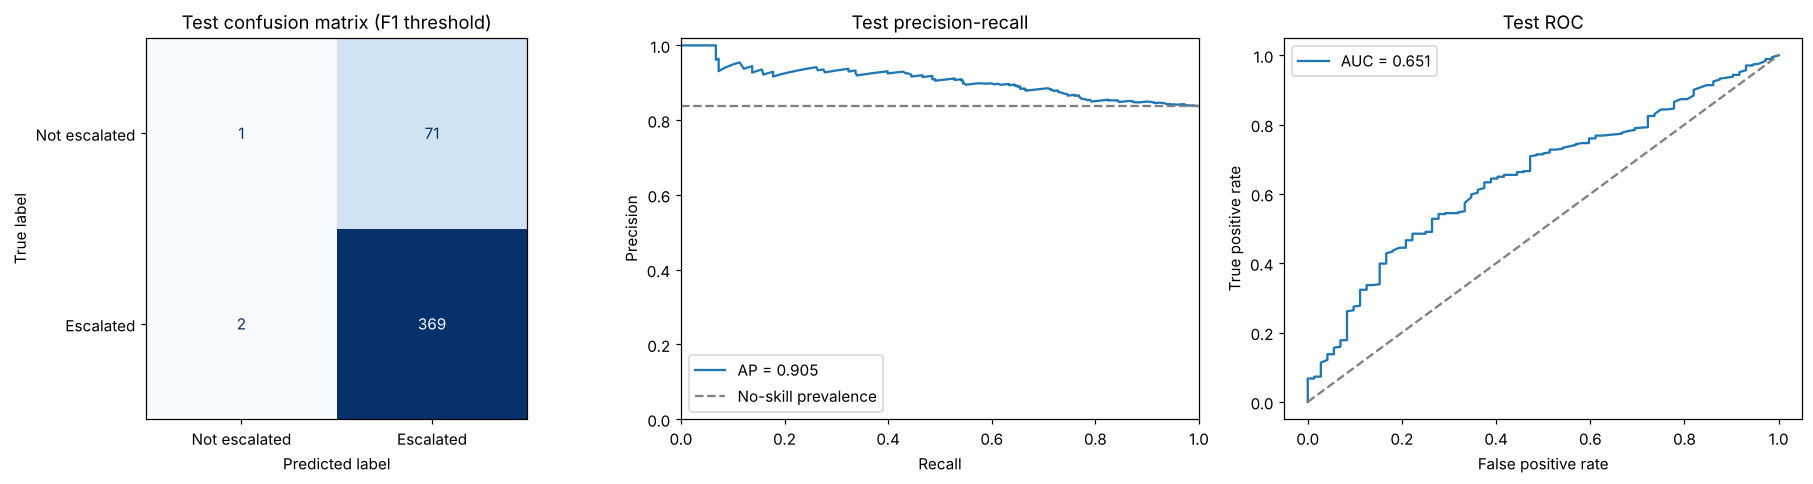

In [7]:
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
ConfusionMatrixDisplay.from_predictions(y['test'],scores['test']>=threshold,
    display_labels=['Not escalated','Escalated'],cmap='Blues',colorbar=False,ax=axes[0])
axes[0].set_title('Test confusion matrix (F1 threshold)')
p,r,_=precision_recall_curve(y['test'],scores['test'])
axes[1].plot(r,p,label=f"AP = {average_precision_score(y['test'],scores['test']):.3f}")
axes[1].axhline(y['test'].mean(),ls='--',color='grey',label='No-skill prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Test precision-recall',xlim=(0,1),ylim=(0,1.02));axes[1].legend()
fpr,tpr,_=roc_curve(y['test'],scores['test'])
axes[2].plot(fpr,tpr,label=f"AUC = {roc_auc_score(y['test'],scores['test']):.3f}")
axes[2].plot([0,1],[0,1],'--',color='grey');axes[2].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC');axes[2].legend()
fig.tight_layout();fig.savefig(RESULTS/'evaluation_charts.png',dpi=160);plt.show()

## Experiment 2: reduce false positives while preserving escalation recall
Provisional requirement (a working assumption to confirm with stakeholders): **at least 90% escalation recall on validation**. Among feasible thresholds, minimise validation false positives; ties favour higher recall, then a higher threshold. The encoder and classifier are unchanged; only the operating threshold changes, so ranking metrics do not change. The test set was already examined in Experiment 1, so test results here are descriptive comparisons, not a fresh holdout.

F1 threshold: 0.1861 | recall>=90% threshold: 0.4019
               precision    recall  f1-score   support

not_escalated       0.26      0.18      0.21        72
    escalated       0.85      0.90      0.87       371

     accuracy                           0.78       443
    macro avg       0.55      0.54      0.54       443
 weighted avg       0.75      0.78      0.77       443



,validation-selected reduced-FP operating point
threshold,0.4019
tp,259.0000
fp,42.0000
fn,27.0000
tn,10.0000
recall,0.9056
precision,0.8605
f1,0.8825
alert_rate,0.8905


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
0,svm_F1_threshold,validation,338,0.1861,0.8462,0.5000,0.8462,1.0000,0.9167,0.9330,0.7132,1.0000,0,52,0,286
1,svm_recall90_threshold,validation,338,0.4019,0.7959,0.5490,0.8605,0.9056,0.8825,0.9330,0.7132,0.8905,10,42,27,259
2,svm_F1_threshold,test,443,0.1861,0.8352,0.5042,0.8386,0.9946,0.9100,0.9053,0.6506,0.9932,1,71,2,369
3,svm_recall90_threshold,test,443,0.4019,0.7833,0.5404,0.8499,0.9003,0.8743,0.9053,0.6506,0.8871,13,59,37,334


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
0,svm_recall90_threshold,test_unseen_text,151,0.4019,0.8543,0.556,0.875,0.9692,0.9197,0.9108,0.669,0.9536,3,18,4,126


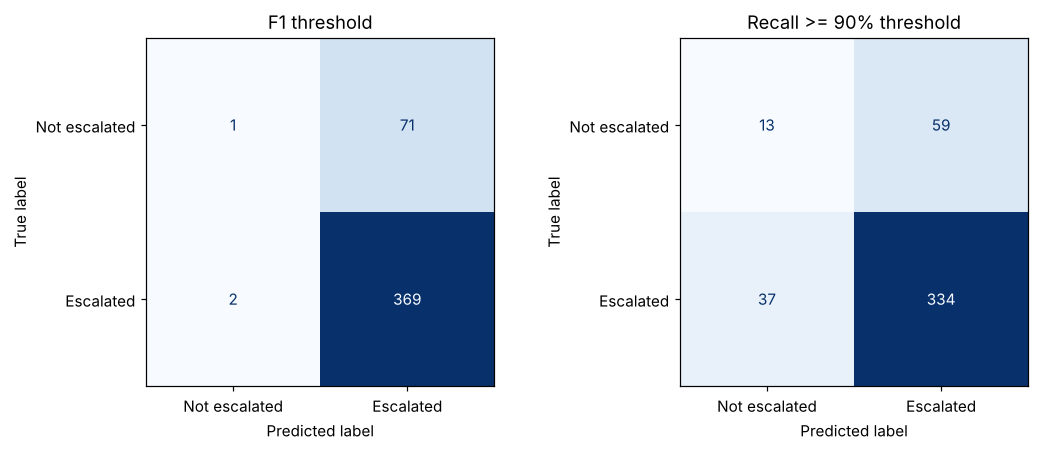

In [8]:
fp_table, chosen = pick_recall_threshold(y['validation'], scores['validation'])
reduced_fp_threshold = float(chosen.threshold)
fp_table.to_csv(RESULTS/'false_positive_threshold_candidates.csv', index=False)
display(chosen.to_frame('validation-selected reduced-FP operating point').round(4))
print('F1 threshold:',round(threshold,4),'| recall>=90% threshold:',round(reduced_fp_threshold,4))
comparison=[]
for s in ['validation','test']:
    comparison.append(evaluate('svm_F1_threshold',s,y[s],scores[s],threshold))
    comparison.append(evaluate('svm_recall90_threshold',s,y[s],scores[s],reduced_fp_threshold))
    out=frames[s].copy(); out['risk_score']=scores[s]; out['alert_threshold']=reduced_fp_threshold
    out['prediction']=(scores[s]>=reduced_fp_threshold).astype(int); out['correct']=out.prediction.eq(out.escalation_label)
    out.to_csv(RESULTS/f'{s}_predictions_reduced_fp.csv',index=False)
comparison=pd.DataFrame(comparison); comparison.to_csv(RESULTS/'false_positive_comparison.csv',index=False)
display(comparison.round(4))
print(classification_report(y['test'],scores['test']>=reduced_fp_threshold,target_names=['not_escalated','escalated'],zero_division=0))
seen_before_test=set(frames['train'].model_text)|set(frames['validation'].model_text)
unseen=~frames['test'].model_text.isin(seen_before_test).to_numpy()
unseen_result=evaluate('svm_recall90_threshold','test_unseen_text',y['test'][unseen],scores['test'][unseen],reduced_fp_threshold)
display(pd.DataFrame([unseen_result]).round(4)); pd.DataFrame([unseen_result]).to_csv(RESULTS/'unseen_text_reduced_fp.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
for ax,t,title in zip(axes,[threshold,reduced_fp_threshold],['F1 threshold','Recall >= 90% threshold']):
    ConfusionMatrixDisplay.from_predictions(y['test'],scores['test']>=t,display_labels=['Not escalated','Escalated'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(title)
fig.tight_layout();fig.savefig(RESULTS/'confusion_matrix_comparison.png',dpi=160);plt.show()
# Default saved model uses the recall-targeted threshold; the original artifact is retained separately.
joblib.dump({'classifier':model,'threshold':reduced_fp_threshold,'encoder_name':MODEL_ID,'encoder_backend':ENCODER_BACKEND,
    'normalize_embeddings':True,'max_seq_length':256,'feature':'model_text','score':'decision_function',
    'threshold_policy':'minimise validation FP subject to recall >= 0.90'},RESULTS/'escalation_model_svm.joblib')
restored=joblib.load(RESULTS/'escalation_model_svm.joblib')
assert np.allclose(restored['classifier'].decision_function(X['test']),scores['test'])
assert restored['threshold']==reduced_fp_threshold

## Experiment 3: text + category + subcategory + assumed initial priority
**Assumption:** the supplied category, subcategory and priority are the correct *initial* values. The export has no verified initial snapshots, so results are conditional on that. Assignment group and outcome fields are not used. One-hot encoding is fitted on training data only, with missing values explicit and unseen categories allowed. C is selected by validation average precision, then the threshold minimises validation false positives subject to ≥ 90% recall.

Text dims: 384 | one-hot dims: 55 | total: 439
               precision    recall  f1-score   support

not_escalated       0.38      0.25      0.30        72
    escalated       0.86      0.92      0.89       371

     accuracy                           0.81       443
    macro avg       0.62      0.58      0.60       443
 weighted avg       0.78      0.81      0.79       443

Checks passed: aligned joins, train-only encoding, convergence, saved-model reproduction, unknown categories.


,C,validation_average_precision
1,0.10,0.9451
0,0.01,0.9439
2,1.00,0.9437
3,10.00,0.9394
4,100.00,0.9312


,validation operating point (text + structured)
threshold,0.3332
tp,264.0000
fp,39.0000
fn,22.0000
tn,13.0000
recall,0.9231
precision,0.8713
f1,0.8964
alert_rate,0.8964


,model,split,n,threshold,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
0,text_only_recall90,validation,338,0.4019,0.7959,0.5490,0.8605,0.9056,0.8825,0.9330,0.7132,0.8905,10,42,27,259
1,text_plus_structured_recall90,validation,338,0.3332,0.8195,0.5865,0.8713,0.9231,0.8964,0.9451,0.7608,0.8964,13,39,22,264
2,text_only_recall90,test,443,0.4019,0.7833,0.5404,0.8499,0.9003,0.8743,0.9053,0.6506,0.8871,13,59,37,334
3,text_plus_structured_recall90,test,443,0.3332,0.8104,0.5846,0.8633,0.9191,0.8903,0.9272,0.7297,0.8916,18,54,30,341


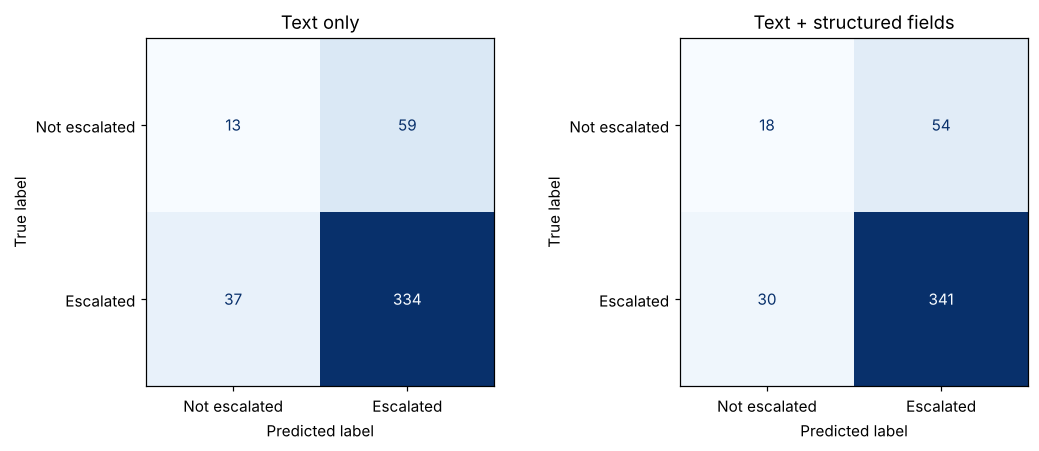

In [9]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import csr_matrix, hstack
STRUCTURED_FIELDS=['category','subcategory','priority']
metadata=pd.read_csv(BASE/'data/assumed_initial_fields.csv',dtype=str)
assert metadata.ticket_id.is_unique
structured={}
for s,d in frames.items():
    joined=d[['ticket_id']].merge(metadata,on='ticket_id',how='left',validate='one_to_one',indicator=True)
    assert joined['_merge'].eq('both').all() and joined.ticket_id.tolist()==d.ticket_id.tolist()
    structured[s]=joined[STRUCTURED_FIELDS].fillna('__MISSING__').replace('', '__MISSING__')
onehot=OneHotEncoder(handle_unknown='ignore',sparse_output=True,dtype=np.float64).fit(structured['train'])
combined_X={s:hstack([csr_matrix(X[s]),onehot.transform(structured[s])],format='csr') for s in frames}
print('Text dims:',EMB_DIM,'| one-hot dims:',len(onehot.get_feature_names_out()),'| total:',combined_X['train'].shape[1])
cand=[];cmodels={}
for C in C_GRID:
    clf=fit_svm(C,combined_X['train'],y['train'])
    cand.append({'C':C,'validation_average_precision':average_precision_score(y['validation'],clf.decision_function(combined_X['validation']))})
    cmodels[C]=clf
combined_selection=pd.DataFrame(cand).sort_values(['validation_average_precision','C'],ascending=[False,True])
combined_C=float(combined_selection.iloc[0].C); combined_model=cmodels[combined_C]
combined_scores={s:combined_model.decision_function(combined_X[s]) for s in frames}
_,combined_choice=pick_recall_threshold(y['validation'],combined_scores['validation'])
combined_threshold=float(combined_choice.threshold)
display(combined_selection.round(4)); display(combined_choice.to_frame('validation operating point (text + structured)').round(4))
structured_comparison=[]
for s in ['validation','test']:
    structured_comparison.append(evaluate('text_only_recall90',s,y[s],scores[s],reduced_fp_threshold))
    structured_comparison.append(evaluate('text_plus_structured_recall90',s,y[s],combined_scores[s],combined_threshold))
    out=frames[s].copy()
    for f in STRUCTURED_FIELDS: out[f]=structured[s][f].to_numpy()
    out['risk_score']=combined_scores[s]; out['alert_threshold']=combined_threshold
    out['prediction']=(combined_scores[s]>=combined_threshold).astype(int); out['correct']=out.prediction.eq(out.escalation_label)
    out.to_csv(RESULTS/f'{s}_predictions_structured.csv',index=False)
structured_comparison=pd.DataFrame(structured_comparison); structured_comparison.to_csv(RESULTS/'structured_comparison.csv',index=False)
display(structured_comparison.round(4))
print(classification_report(y['test'],combined_scores['test']>=combined_threshold,target_names=['not_escalated','escalated'],zero_division=0))
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
for ax,sc,t,title in [(axes[0],scores['test'],reduced_fp_threshold,'Text only'),(axes[1],combined_scores['test'],combined_threshold,'Text + structured fields')]:
    ConfusionMatrixDisplay.from_predictions(y['test'],sc>=t,display_labels=['Not escalated','Escalated'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(title)
fig.tight_layout();fig.savefig(RESULTS/'structured_confusion_comparison.png',dpi=160);plt.show()
combined_artifact={'classifier':combined_model,'onehot':onehot,'structured_fields':STRUCTURED_FIELDS,'threshold':combined_threshold,
    'encoder_name':MODEL_ID,'encoder_backend':ENCODER_BACKEND,'normalize_embeddings':True,'max_seq_length':256,'feature':'model_text',
    'assume_initial_fields':True,'score':'decision_function','threshold_policy':'minimise validation FP with recall >= 0.90'}
joblib.dump(combined_artifact,RESULTS/'escalation_model_svm_structured.joblib')
rc=joblib.load(RESULTS/'escalation_model_svm_structured.joblib')
rebuilt=hstack([csr_matrix(X['test']),rc['onehot'].transform(structured['test'])],format='csr')
assert np.allclose(rc['classifier'].decision_function(rebuilt),combined_scores['test'])
probe=pd.DataFrame([{'category':'UNSEEN_TEST_CATEGORY','subcategory':'__MISSING__','priority':'__MISSING__'}])
assert rc['onehot'].transform(probe).shape[1]==len(onehot.get_feature_names_out())
print('Checks passed: aligned joins, train-only encoding, convergence, saved-model reproduction, unknown categories.')

## Experiment 4: nested five-fold grouped cross-validation
**Question:** does the model generalise to held-out *groups* rather than seeing the same cleaned description or incident/problem group in training?

All eligible tickets from the three partitions are combined. Connected groups are built so that tickets sharing either exact cleaned `model_text` or `event_group_id` (including transitive links) stay together. Five outer stratified group folds evaluate the text-only and text + structured SVMs. Inside each outer training set, three inner grouped folds select C by out-of-fold average precision and an alert threshold that minimises false positives subject to ≥ 90% inner out-of-fold recall. One-hot encoders are fitted on the current training fold only. The frozen pretrained text embeddings need no fitting and are reused. Models are then refit on the outer training set and predict only the held-out fold.

This mixes dates deliberately and answers a different question from the chronological split. It is exploratory: these records already informed the earlier experiments.

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
all_data=pd.concat([frames[s] for s in ['train','validation','test']],ignore_index=True)
all_embeddings=np.vstack([X[s] for s in ['train','validation','test']])
all_metadata=pd.concat([structured[s] for s in ['train','validation','test']],ignore_index=True)
all_y=all_data.escalation_label.to_numpy(dtype=int)
assert all_data.ticket_id.is_unique
parents=list(range(len(all_data)))
def find_group(i):
    while parents[i]!=i:
        parents[i]=parents[parents[i]];i=parents[i]
    return i
for col in ['model_text','event_group_id']:
    first={}
    for i,v in enumerate(all_data[col]):
        if pd.isna(v):continue
        if v in first:parents[find_group(i)]=find_group(first[v])
        else:first[v]=i
groups=pd.factorize(np.array([find_group(i) for i in range(len(all_data))]))[0]
outer_splits=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(all_embeddings,all_y,groups))
assignments=all_data[['ticket_id','event_group_id','text_group_id','escalation_label']].copy()
assignments['connected_group']=groups; assignments['outer_fold']=-1
for fold,(tr,te) in enumerate(outer_splits,1):
    assert set(groups[tr]).isdisjoint(groups[te])
    for col in ['model_text','event_group_id']:
        assert set(all_data.iloc[tr][col]).isdisjoint(all_data.iloc[te][col])
    assert len(np.unique(all_y[te]))==2 and len(np.unique(all_y[tr]))==2
    assignments.loc[te,'outer_fold']=fold
assert (assignments.outer_fold>0).all()
assignments.to_csv(RESULTS/'grouped_fold_assignments.csv',index=False)
sizes=pd.Series(groups).value_counts()
print('Tickets:',len(all_data),'| connected groups:',len(sizes),'| largest group:',sizes.max())
fold_summary=assignments.groupby('outer_fold').agg(tickets=('ticket_id','size'),escalated=('escalation_label','sum'),groups=('connected_group','nunique'))
fold_summary['not_escalated']=fold_summary.tickets-fold_summary.escalated
fold_summary['escalation_rate']=fold_summary.escalated/fold_summary.tickets
display(fold_summary); fold_summary.to_csv(RESULTS/'grouped_fold_summary.csv')

Tickets: 2625 | connected groups: 937 | largest group: 343


,tickets,escalated,groups,not_escalated,escalation_rate
outer_fold,,,,,
1,523,445,155,78,0.850860
2,528,447,188,81,0.846591
3,524,445,197,79,0.849237
4,524,446,198,78,0.851145
5,526,447,199,79,0.849810


In [11]:
VARIANTS=['text_only','text_plus_structured']
def fold_features(train_idx,eval_idx,use_structured):
    tx=csr_matrix(all_embeddings[train_idx]); ex=csr_matrix(all_embeddings[eval_idx])
    if use_structured:
        enc=OneHotEncoder(handle_unknown='ignore',sparse_output=True,dtype=np.float64)
        tx=hstack([tx,enc.fit_transform(all_metadata.iloc[train_idx])],format='csr')
        ex=hstack([ex,enc.transform(all_metadata.iloc[eval_idx])],format='csr')
    return tx,ex
fold_rows=[];selection_audit=[];oof_parts=[]
t0=time.time()
for fold,(otr,ote) in enumerate(outer_splits,1):
    inner=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+fold).split(all_embeddings[otr],all_y[otr],groups[otr]))
    for variant in VARIANTS:
        use_s=variant=='text_plus_structured'
        feats=[]
        for itr,iva in inner:
            it,iv=otr[itr],otr[iva]
            assert set(groups[it]).isdisjoint(groups[iv]) and len(np.unique(all_y[it]))==2 and len(np.unique(all_y[iv]))==2
            tx,vx=fold_features(it,iv,use_s); feats.append((it,iva,tx,vx))
        cand_scores={};cand_ap={}
        for C in C_GRID:
            oof_inner=np.full(len(otr),np.nan)
            for it,iva,tx,vx in feats:
                oof_inner[iva]=fit_svm(C,tx,all_y[it]).decision_function(vx)
            assert np.isfinite(oof_inner).all()
            cand_scores[C]=oof_inner; cand_ap[C]=average_precision_score(all_y[otr],oof_inner)
            selection_audit.append({'outer_fold':fold,'model':variant,'C':C,'inner_oof_average_precision':cand_ap[C]})
        sel_C=max(C_GRID,key=lambda c:(cand_ap[c],-c))
        _,pick=pick_recall_threshold(all_y[otr],cand_scores[sel_C])
        thr=float(pick.threshold)
        tx,ex=fold_features(otr,ote,use_s)
        sc=fit_svm(sel_C,tx,all_y[otr]).decision_function(ex)
        row=evaluate(variant,f'outer_fold_{fold}',all_y[ote],sc,thr); row.update({'outer_fold':fold,'selected_C':sel_C,
            'inner_recall_at_threshold':float(pick.recall)})
        fold_rows.append(row)
        part=all_data.iloc[ote][['ticket_id','escalation_label']].copy(); part['model']=variant; part['outer_fold']=fold
        part['risk_score']=sc; part['threshold']=thr; part['prediction']=(sc>=thr).astype(int); oof_parts.append(part)
fold_metrics=pd.DataFrame(fold_rows); oof=pd.concat(oof_parts,ignore_index=True)
pd.DataFrame(selection_audit).to_csv(RESULTS/'grouped_selection_audit.csv',index=False)
fold_metrics.to_csv(RESULTS/'grouped_fold_metrics.csv',index=False); oof.to_csv(RESULTS/'grouped_oof_predictions.csv',index=False)
print(f'Nested CV finished in {time.time()-t0:.0f}s; all SVM fits converged.')
display(fold_metrics[['model','outer_fold','selected_C','threshold','precision','recall','f1','average_precision','roc_auc','alert_rate','fp','fn']].round(4))

Nested CV finished in 83s; all SVM fits converged.


,model,outer_fold,selected_C,threshold,precision,recall,f1,average_precision,roc_auc,alert_rate,fp,fn
0,text_only,1,0.10,0.4291,0.8794,0.7371,0.8020,0.9237,0.6791,0.7132,45,117
1,text_plus_structured,1,0.10,0.3232,0.8739,0.8876,0.8807,0.9416,0.7401,0.8642,57,50
2,text_only,2,0.01,0.5550,0.8485,0.9150,0.8805,0.9186,0.6870,0.9129,73,38
3,text_plus_structured,2,0.01,0.4324,0.8651,0.9329,0.8977,0.9506,0.7831,0.9129,65,30
4,text_only,3,0.01,0.5349,0.8615,0.9506,0.9038,0.9272,0.7021,0.9370,68,22
5,text_plus_structured,3,0.01,0.4166,0.8879,0.9079,0.8978,0.9457,0.7663,0.8683,51,41
6,text_only,4,0.01,0.5623,0.8678,0.8834,0.8756,0.9238,0.7039,0.8664,60,52
7,text_plus_structured,4,0.01,0.4419,0.8753,0.8812,0.8782,0.9414,0.7439,0.8569,56,53
8,text_only,5,0.01,0.5514,0.8658,0.9239,0.8939,0.9276,0.7018,0.9068,64,34
9,text_plus_structured,5,0.01,0.4290,0.8690,0.9642,0.9141,0.9448,0.7729,0.9430,65,16


,model,tickets,accuracy,balanced_accuracy,precision,recall,f1,average_precision,roc_auc,alert_rate,tn,fp,fn,tp
0,text_only,2625,0.7817,0.5486,0.8639,0.8821,0.8729,0.9229,0.6909,0.8674,85,310,263,1967
1,text_plus_structured,2625,0.8156,0.5852,0.8740,0.9148,0.8940,0.9437,0.7560,0.8891,101,294,190,2040
2,always_alert,2625,0.8495,0.5000,0.8495,1.0000,0.9186,0.8495,0.5000,1.0000,0,395,0,2230


precision                          recall                              f1                         average_precision                         roc_auc                         alert_rate                       
                          mean     std     min     max    mean     std     min     max    mean     std     min     max              mean     std     min     max    mean     std     min     max       mean     std     min    max
model                                                                                                                                                                                                                             
text_only               0.8646  0.0111  0.8485  0.8794  0.8820  0.0845  0.7371  0.9506  0.8712  0.0403  0.8020  0.9038            0.9242  0.0036  0.9186  0.9276  0.6948  0.0111  0.6791  0.7039     0.8673  0.0898  0.7132  0.937
text_plus_structured    0.8742  0.0086  0.8651  0.8879  0.9148  0.0342  0.8812  0.9642  0.8937  0.0146  0.8782  0.9141            0.9448  0.0037  0.9414  0.9506  0.7612  0.0186  0.7401  0.7831     0.8891  0.0373  0.8569  0.943

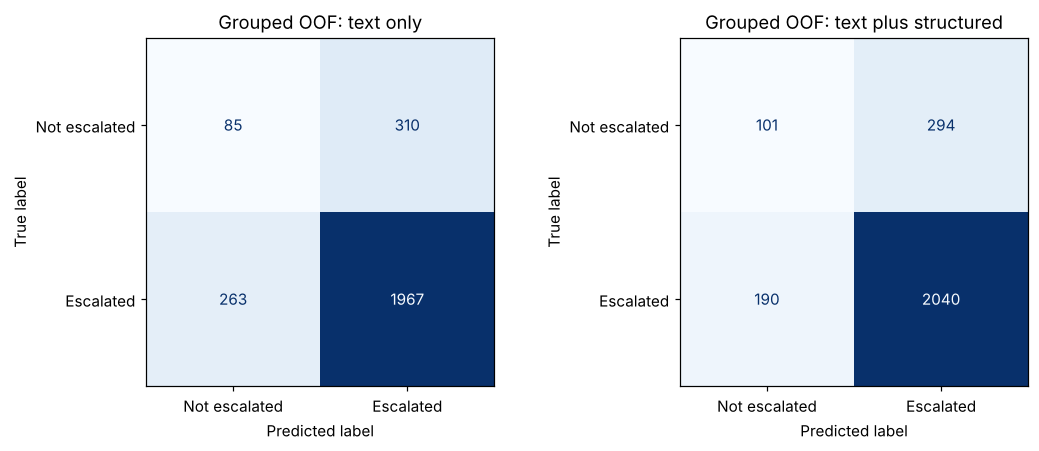

In [12]:
pooled_rows=[]
for variant in VARIANTS:
    d=oof[oof.model==variant]
    assert len(d)==len(all_data) and d.ticket_id.is_unique
    truth=d.escalation_label.to_numpy();pred=d.prediction.to_numpy();score=d.risk_score.to_numpy()
    tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    pooled_rows.append({'model':variant,'tickets':len(d),'accuracy':accuracy_score(truth,pred),
        'balanced_accuracy':balanced_accuracy_score(truth,pred),'precision':precision_score(truth,pred,zero_division=0),
        'recall':recall_score(truth,pred),'f1':f1_score(truth,pred),'average_precision':average_precision_score(truth,score),
        'roc_auc':roc_auc_score(truth,score),'alert_rate':pred.mean(),'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)})
pooled_rows.append({'model':'always_alert','tickets':len(all_y),'accuracy':all_y.mean(),'balanced_accuracy':0.5,
    'precision':all_y.mean(),'recall':1.,'f1':2*all_y.mean()/(1+all_y.mean()),'average_precision':all_y.mean(),
    'roc_auc':0.5,'alert_rate':1.,'tn':0,'fp':int((all_y==0).sum()),'fn':0,'tp':int(all_y.sum())})
pooled=pd.DataFrame(pooled_rows); pooled.to_csv(RESULTS/'grouped_pooled_metrics.csv',index=False)
display(pooled.round(4))
metric_cols=['precision','recall','f1','average_precision','roc_auc','alert_rate']
fold_variability=fold_metrics.groupby('model')[metric_cols].agg(['mean','std','min','max'])
fold_variability.to_csv(RESULTS/'grouped_fold_variability.csv'); display(fold_variability.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4.2))
for ax,variant in zip(axes,VARIANTS):
    d=oof[oof.model==variant]
    ConfusionMatrixDisplay.from_predictions(d.escalation_label,d.prediction,display_labels=['Not escalated','Escalated'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title('Grouped OOF: '+variant.replace('_',' '))
fig.tight_layout();fig.savefig(RESULTS/'grouped_confusion_comparison.png',dpi=160);plt.show()

Pooled confusion counts sum held-out predictions across all five outer folds; each ticket receives one held-out prediction per variant using a fold-specific threshold. Pooled AP/AUC mix scores from five different fitted models, so also read the per-fold means and spread. Standard deviations describe variation across five folds, not independent confidence intervals. Do not compare pooled counts directly with the single chronological test set: they cover different tickets and different questions.

## Reproducibility checks and manifest

In [13]:
saved=pd.read_csv(RESULTS/'test_predictions.csv')
assert np.array_equal(saved.prediction,(saved.risk_score>=threshold).astype(int)) and len(saved)==len(frames['test'])
assert model.coef_.shape[1]==EMB_DIM          # the text-only model consumes only the embedding
def ver(k):
    try: return importlib.metadata.version(k)
    except Exception: return None
manifest={'encoder':MODEL_ID,'ENCODER_BACKEND':ENCODER_BACKEND,'seed':SEED,'classifier':'sklearn.svm.LinearSVC(squared_hinge)',
    'selected_C_text_only':best_C,'selected_C_structured':combined_C,'threshold_f1':threshold,
    'threshold_recall90_text_only':reduced_fp_threshold,'threshold_recall90_structured':combined_threshold,
    'selection_metric':'validation average precision','min_recall_policy':MIN_RECALL,
    'versions':{k:ver(k) for k in ['sentence-transformers','transformers','torch','scikit-learn','numpy','pandas','matplotlib','joblib','scipy']},
    'python':platform.python_version(),
    'data_sha256':{s:hashlib.sha256((BASE/'data'/f'{s}.csv').read_bytes()).hexdigest() for s in frames},
    'limitations':['synthetic data','retrospective labels','initial snapshots unverified','repeated text templates','scores are SVM margins (uncalibrated)']}
(RESULTS/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
print('Passed: split integrity, group separation, text validation, embedding dimensions, convergence, saved-model reproduction.')
print('ENCODER BACKEND:',ENCODER_BACKEND)

Passed: split integrity, group separation, text validation, embedding dimensions, convergence, saved-model reproduction.
ENCODER BACKEND: STAND-IN: tfidf+svd (NOT sentence embeddings)


# Results highlights
The table and notes below are generated from the executed results, so they refresh on every re-run.

In [14]:
if ENCODER_BACKEND != 'sentence-transformers':
    print('*' * 90); print('WARNING: this run used the', ENCODER_BACKEND); print('Numbers are indicative only. Re-run with all-MiniLM-L6-v2 for the real sentence-embedding results.'); print('*' * 90)
t = lambda m,s: next(r for r in rows_all if r['model']==m and r['split']==s)
rows_all = metrics.to_dict('records') + comparison.to_dict('records') + structured_comparison.to_dict('records')
tbl = []
for label, m in [('Always alert (benchmark)','always_alert'),('SVM, F1 threshold','svm_tuned_F1'),
                 ('SVM, recall>=90% threshold','svm_recall90_threshold'),('SVM + structured, recall>=90% threshold','text_plus_structured_recall90')]:
    r = t(m,'test'); tbl.append({'Chronological test (443 tickets)':label,'precision':r['precision'],'recall':r['recall'],'f1':r['f1'],
        'avg precision':r['average_precision'],'ROC AUC':r['roc_auc'],'alert rate':r['alert_rate'],'false positives':r['fp'],'missed escalations':r['fn']})
display(pd.DataFrame(tbl).round(4))
g = pooled.set_index('model')
display(g.loc[['text_only','text_plus_structured','always_alert'],['precision','recall','f1','average_precision','roc_auc','alert_rate','fp','fn']].round(4)
        .rename_axis('Grouped CV, pooled held-out (%d tickets)' % len(all_y)))
nonesc = int((all_y==0).sum())
for v in ['text_only','text_plus_structured']:
    print(f"{v}: flags {int(g.loc[v,'fp'])} of {nonesc} non-escalated tickets ({g.loc[v,'fp']/nonesc:.1%}); misses {int(g.loc[v,'fn'])} escalations")

******************************************************************************************
Numbers are indicative only. Re-run with all-MiniLM-L6-v2 for the real sentence-embedding results.
******************************************************************************************
text_only: flags 310 of 395 non-escalated tickets (78.5%); misses 263 escalations
text_plus_structured: flags 294 of 395 non-escalated tickets (74.4%); misses 190 escalations


,Chronological test (443 tickets),precision,recall,f1,avg precision,ROC AUC,alert rate,false positives,missed escalations
0,Always alert (benchmark),0.8375,1.0000,0.9115,0.8375,0.5000,1.0000,72,0
1,"SVM, F1 threshold",0.8386,0.9946,0.9100,0.9053,0.6506,0.9932,71,2
2,"SVM, recall>=90% threshold",0.8499,0.9003,0.8743,0.9053,0.6506,0.8871,59,37
3,"SVM + structured, recall>=90% threshold",0.8633,0.9191,0.8903,0.9272,0.7297,0.8916,54,30


,precision,recall,f1,average_precision,roc_auc,alert_rate,fp,fn
"Grouped CV, pooled held-out (2625 tickets)",,,,,,,,
text_only,0.8639,0.8821,0.8729,0.9229,0.6909,0.8674,310,263
text_plus_structured,0.8740,0.9148,0.8940,0.9437,0.7560,0.8891,294,190
always_alert,0.8495,1.0000,0.9186,0.8495,0.5000,1.0000,395,0


## How to read these results
* **Escalations are ~85% of tickets**, so *always alerting* already scores F1 ≈ 0.91-0.92. F1 alone cannot show the model is useful; read false positives, missed escalations and ranking (average precision, ROC AUC) against that benchmark.
* **The F1-optimal threshold degenerates to "alert on (almost) everything"** (as in Approach 3). It adds no workload reduction. The recall ≥ 90% threshold is the usable operating point because it forces a trade-off.
* **Ranking signal is modest** (ROC AUC ≈ 0.65-0.76). Category / subcategory / priority add a consistent lift under both the chronological split and grouped cross-validation.
* **Test results were examined repeatedly** and the data is synthetic with repeated templates: treat all figures as descriptive and prototype-level, not as evidence of live early-warning accuracy.